# Benchmark 1: Pitchfork Bifurcation

Supercritical pitchfork normal form:
$$\dot{u} = f(u, \mu) = -u^3 + \mu u$$

1. Oscillating roots vs. branch-approximating solutions by degree continuation.
2. Convergence of the upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ in the smooth, boundary-singularity, and interior-singularity regimes.

In [26]:
import sys
sys.path.append("..")

import numpy as np
import matplotlib.pyplot as plt
from pce_galerkin import PCEGalerkin, set_plot_style

set_plot_style(usetex=True)

def rhs(u, mu):
    return -u**3 + mu[None, :] * u

def jac(u, mu):
    return (-3.0 * u**2 + mu[None, :])[None, :, :]

def exact_upper(mu):
    return np.sqrt(np.maximum(mu, 0.0))[None, :]

## 1. Oscillating roots and degree continuation

Random coefficient initializations produce oscillating solutions, while degree continuation isolates the branch-approximating solutions.

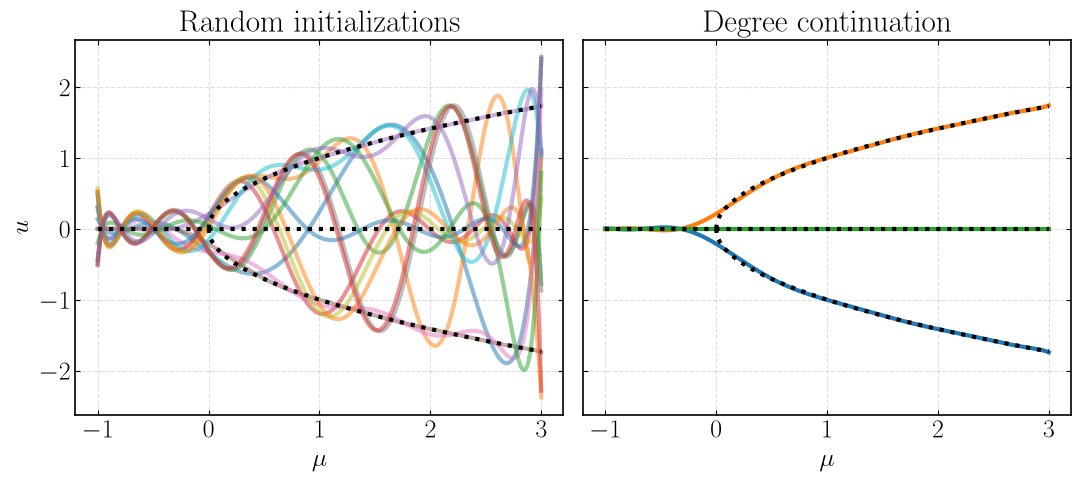

In [27]:
mu_bounds = (-1.0, 3.0)
N = 10
n_samples = 20
seed = 2

solver = PCEGalerkin(rhs, jac, mu_bounds=mu_bounds, state_dim=1, quad_order=2 * N + 1)

all_roots = solver.random_roots(N, n_samples=n_samples, seed=seed, scale=0.8)
branches = solver.find_branches(N, n_samples=n_samples, seed=seed, unique_tol=1e-6, box=(-2, 2))

fig, axes = plt.subplots(1, 2, figsize=(11, 5), sharey=True)

mu_all = np.linspace(mu_bounds[0], mu_bounds[1], 400)
mu_pos = np.linspace(0.0, mu_bounds[1], 300)

for c in all_roots:
    mu_g, u_g = solver.eval(c)
    axes[0].plot(mu_g, u_g[0], alpha=0.5)
    
axes[0].plot(mu_all, np.zeros_like(mu_all), "k:", lw=3.0, zorder=5)
axes[0].plot(mu_pos, np.sqrt(mu_pos), "k:", lw=3.0, zorder=5)
axes[0].plot(mu_pos, -np.sqrt(mu_pos), "k:", lw=3.0, zorder=5)
axes[0].set_title("Random initializations")
axes[0].set_xlabel(r"$\mu$")
axes[0].set_ylabel(r"$u$")
axes[0].grid(True, linestyle="--", alpha=0.4)

for c in branches:
    mu_g, u_g = solver.eval(c)
    axes[1].plot(mu_g, u_g[0])
    
axes[1].plot(mu_all, np.zeros_like(mu_all), "k:", lw=3.0, zorder=5)
axes[1].plot(mu_pos, np.sqrt(mu_pos), "k:", lw=3.0, zorder=5)
axes[1].plot(mu_pos, -np.sqrt(mu_pos), "k:", lw=3.0, zorder=5)
axes[1].set_title("Degree continuation")
axes[1].set_xlabel(r"$\mu$")
axes[1].grid(True, linestyle="--", alpha=0.4)

plt.tight_layout()
plt.show()

## 2. Convergence across regularity regimes

Upper branch $\bar{u}_+(\mu) = \sqrt{\mu}\,\chi_{[0,\infty)}(\mu)$ on three regimes:
- Smooth: $I = [0.2, 1]$
- Boundary singularity: $I = [0, 1]$
- Interior singularity: $I = [-1, 3]$

In [28]:
def plot_regime(name, bounds, ref_rates, N_max, plot_degrees):
    a, b = bounds
    degrees = np.arange(1, N_max + 1)
    anchor_idx = int(0.6 * len(degrees))
    anchor_scale = 1.6

    solver = PCEGalerkin(rhs, jac, mu_bounds=bounds, state_dim=1, quad_order=2 * N_max + 1)
    history = solver.continuation(N_max, u0=[1.0], return_history=True)

    fig, (ax_branch, ax_conv) = plt.subplots(1, 2, figsize=(11, 4.5))

    mu_ex = np.linspace(a, b, 600)
    ax_branch.plot(mu_ex, exact_upper(mu_ex)[0], "k-", lw=3.5, label=r"Exact $\bar{u}_+$")
    for N in plot_degrees:
        mu_g, u_g = solver.eval(history[N])
        ax_branch.plot(mu_g, u_g[0], "--", lw=3.0, label=rf"$N={N}$")
    ax_branch.set_title(f"{name}")
    ax_branch.set_xlabel(r"$\mu$")
    ax_branch.set_ylabel(r"$u$")
    ax_branch.grid(True, linestyle="--", alpha=0.4)
    ax_branch.legend(loc="lower right", framealpha=0.85)

    err_l2, err_linf, res_ls = [], [], []
    for N in degrees:
        e2, einf, r = solver.errors(history[int(N)], exact_upper)
        err_l2.append(e2)
        err_linf.append(einf)
        res_ls.append(r)

    ax_conv.semilogy(degrees, err_l2, "-", color="#065895", label=r"$\|\bar{u} - u_N\|_{L^2}$")
    ax_conv.semilogy(degrees, err_linf, "-", color="#77ac30", label=r"$\|\bar{u} - u_N\|_{L^\infty}$")
    ax_conv.semilogy(degrees, res_ls, "-", color="#f79a25", label=r"$\|\mathcal{F}(u_{LS,N})\|_{L^2}$")

    curves = {"l2": err_l2, "linf": err_linf, "res": res_ls}
    for label, style, rate_fn, anchor_key in ref_rates:
        target = np.asarray(curves[anchor_key])
        if rate_fn is None:
            # Fit exponential decay rate
            mask = (degrees >= 5) & (target > 1e-13)
            slope, _ = np.polyfit(degrees[mask], np.log(target[mask]), 1)
            rho_est = np.exp(-slope)
            print(f"Estimated rho ({anchor_key}): {rho_est:.4f}")
            ref_curve = rho_est ** (-degrees.astype(float))
        else:
            ref_curve = rate_fn(degrees.astype(float))
        ref_curve *= anchor_scale * target[anchor_idx] / ref_curve[anchor_idx]
        ax_conv.semilogy(degrees, ref_curve, style, color="k", alpha=0.75, label=label)

    ax_conv.set_title("Convergence")
    ax_conv.set_xlabel(r"$N$")
    ax_conv.set_ylabel("Error")
    ax_conv.grid(True, which="both", linestyle="--", alpha=0.4)
    ax_conv.legend(loc="lower left", framealpha=0.85)

    plt.tight_layout()
    plt.show()

### 2.1 Smooth regime

Estimated rho (linf): 2.0468


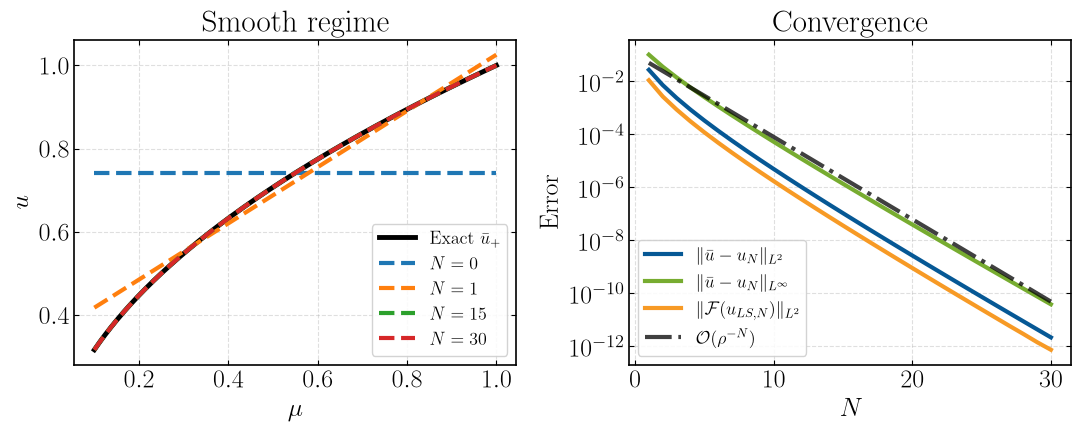

In [29]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]

plot_regime(name="Smooth regime", bounds=(0.1, 1.0),
            ref_rates=[(r"$\mathcal{O}(\rho^{-N})$", "-.", None, "linf")],
            N_max=N_max, plot_degrees=plot_degrees)

### 2.2 Boundary singularity

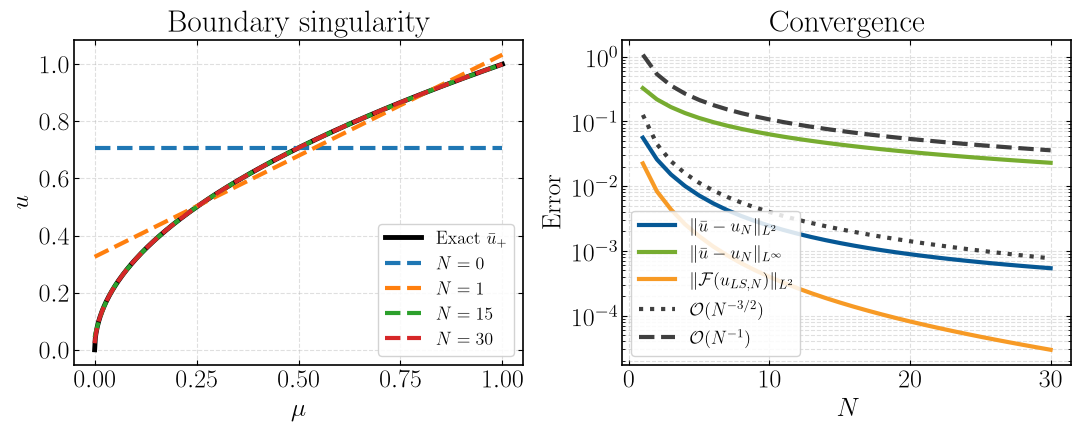

In [30]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]

plot_regime(name="Boundary singularity", bounds=(0.0, 1.0),
            ref_rates=[(r"$\mathcal{O}(N^{-3/2})$", ":", lambda N: N**(-1.5), "l2"),
                       (r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "linf")],
            N_max=N_max, plot_degrees=plot_degrees)

### 2.3 Interior singularity

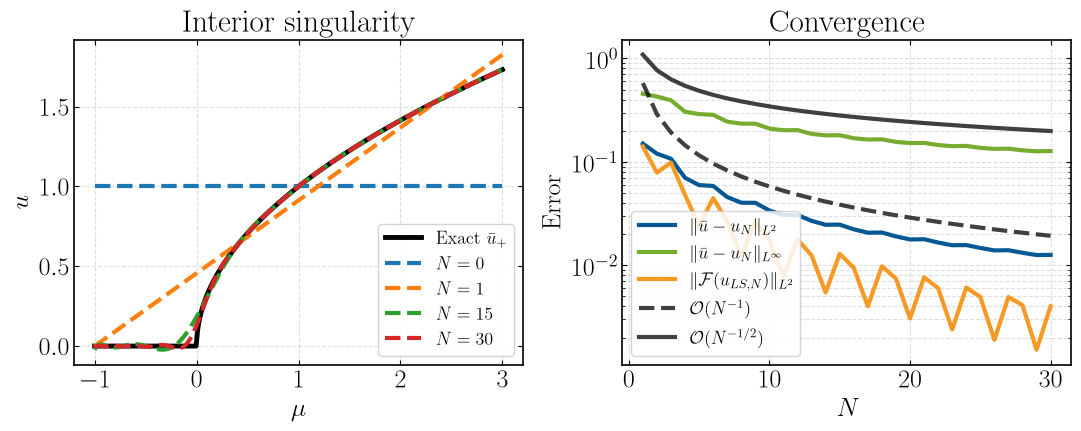

In [31]:
N_max = 30
plot_degrees = [0, 1, N_max // 2, N_max]

plot_regime(name="Interior singularity", bounds=(-1.0, 3.0),
            ref_rates=[(r"$\mathcal{O}(N^{-1})$", "--", lambda N: N**(-1.0), "l2"),
                       (r"$\mathcal{O}(N^{-1/2})$", "-", lambda N: N**(-0.5), "linf")],
            N_max=N_max, plot_degrees=plot_degrees)